In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import pyarrow.parquet as pq
import glob
import gc, psutil
def mem(): print(round(psutil.Process().memory_info().rss / 1e9, 2), "GB used by this notebook")

# Data Loading

**Purpose.** Build one clean, time-ordered table of hard drive health data for a single drive model, for use in failure prediction.

**Source.** Backblaze Hard Drive Data and Stats: daily SMART readings, one row per drive per day, published quarterly. Only the Seagate ST12000NM0008 model is used, because SMART attributes can differ between models.

**Approach**
1. The daily files of each quarter were filtered to the chosen model and saved as one Parquet file per quarter, which reduces disk use and loading time.
2. The training-period quarters (listed in `QUARTERS`) are loaded and joined. The table is sorted by drive and date, dates are converted to datetime, and numbers are stored as float32 to reduce memory.
3. Removed columns: SMART attributes that are empty or constant for this model (raw 3, 10, 183, 184, 189, 191, 196), and the location columns (vault, pod, slot), which are missing in early files and would not be available to an end user.
4. Kept columns: date, serial number, failure label, 19 raw SMART attributes and 5 normalized SMART attributes.

**Held-out data.** Validation and test periods are not loaded in this notebook, so exploration cannot be influenced by them.

**Checks on every loaded quarter.** The failure label contains only 0 and 1, there are no duplicate (drive, date) rows, the kept columns have no missing values, and the removed columns were confirmed empty or constant.

In [2]:
QUARTERS = ["Q1_2023", "Q2_2023", "Q3_2023", "Q4_2023",
            "Q1_2024", "Q2_2024", "Q3_2024", "Q4_2024",
            "Q1_2025", "Q2_2025", "Q3_2025", "Q4_2025"]   # training period only

DROP = ["smart_3_raw", "smart_10_raw", "smart_183_raw", "smart_184_raw",
        "smart_189_raw", "smart_191_raw", "smart_196_raw",
        "vault_id", "pod_id", "pod_slot_num"]

parts = []
for q in QUARTERS:
    part = pd.read_parquet(f"Dataset/seagate_data_{q}.parquet").drop(columns=DROP, errors="ignore")
    part["date"] = pd.to_datetime(part["date"])
    nums = part.select_dtypes("float64").columns
    part[nums] = part[nums].astype("float32")
    print(q, part.shape, "failures:", int(part["failure"].sum()),
          part["date"].min().date(), "to", part["date"].max().date())
    parts.append(part)

df = pd.concat(parts, ignore_index=True)
del parts, part; gc.collect()                                   # new: frees the second copy
df["serial_number"] = df["serial_number"].astype("category")    # new: much smaller than text
df = df.sort_values(["serial_number", "date"]).reset_index(drop=True)
print(df.shape, "| total failures:", int(df["failure"].sum()))
mem()

Q1_2023 (1774769, 27) failures: 120 2023-01-01 to 2023-03-31
Q2_2023 (1763868, 27) failures: 157 2023-04-01 to 2023-06-30
Q3_2023 (1796668, 27) failures: 170 2023-07-01 to 2023-09-30
Q4_2023 (1792831, 27) failures: 126 2023-10-01 to 2023-12-31
Q1_2024 (1766031, 27) failures: 144 2024-01-01 to 2024-03-31
Q2_2024 (1758710, 27) failures: 122 2024-04-01 to 2024-06-30
Q3_2024 (1771930, 27) failures: 126 2024-07-01 to 2024-09-30
Q4_2024 (1763512, 27) failures: 110 2024-10-01 to 2024-12-31
Q1_2025 (1714395, 27) failures: 104 2025-01-01 to 2025-03-31
Q2_2025 (1718302, 27) failures: 138 2025-04-01 to 2025-06-30
Q3_2025 (1728706, 27) failures: 132 2025-07-01 to 2025-09-30
Q4_2025 (1715709, 27) failures: 112 2025-10-01 to 2025-12-31
(21065431, 27) | total failures: 1561
3.5 GB used by this notebook


In [3]:
fail_day = df["date"].where(df["failure"] == 1)
ff = fail_day.groupby(df["serial_number"], observed=True).transform("min")
df = df.loc[ff.isna() | (df["date"] <= ff)].reset_index(drop=True)
del fail_day, ff; gc.collect()

last = df.groupby("serial_number", observed=True)["date"].transform("max")
fr = df.loc[df["failure"] == 1]
print("failed drives:", len(fr), "| failure row is the drive's last row:", (fr["date"] == last[fr.index]).mean())
del last, fr; gc.collect()
df.to_parquet("clean_train.parquet")
mem()

failed drives: 1560 | failure row is the drive's last row: 1.0
3.06 GB used by this notebook


In [4]:
df.head()

,date,serial_number,failure,smart_1_raw,smart_4_raw,smart_5_normalized,smart_5_raw,smart_7_raw,smart_9_raw,smart_12_raw,...,smart_194_raw,smart_195_raw,smart_197_normalized,smart_197_raw,smart_198_normalized,smart_198_raw,smart_199_raw,smart_240_raw,smart_241_raw,smart_242_raw
0,2023-01-01,ZHZ07RNQ,0,224060864.0,3.0,100.0,0.0,673685632.0,27877.0,3.0,...,30.0,224060864.0,100.0,0.0,100.0,0.0,0.0,27704.0,9.535032e+10,3.013587e+11
1,2023-01-02,ZHZ07RNQ,0,123731368.0,3.0,100.0,0.0,679215936.0,27908.0,3.0,...,30.0,123731368.0,100.0,0.0,100.0,0.0,0.0,27735.0,9.540099e+10,3.019401e+11
2,2023-01-03,ZHZ07RNQ,0,186583808.0,3.0,100.0,0.0,682692480.0,27940.0,3.0,...,30.0,186583808.0,100.0,0.0,100.0,0.0,0.0,27767.0,9.546747e+10,3.029131e+11
3,2023-01-04,ZHZ07RNQ,0,180788992.0,3.0,100.0,0.0,684473792.0,27956.0,3.0,...,29.0,180788992.0,100.0,0.0,100.0,0.0,0.0,27783.0,9.550315e+10,3.031157e+11
4,2023-01-05,ZHZ07RNQ,0,223861312.0,3.0,100.0,0.0,688742720.0,27987.0,3.0,...,30.0,223861312.0,100.0,0.0,100.0,0.0,0.0,27814.0,9.556463e+10,3.035856e+11


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21059498 entries, 0 to 21059497
Data columns (total 27 columns):
 #   Column                Dtype         
---  ------                -----         
 0   date                  datetime64[us]
 1   serial_number         category      
 2   failure               int64         
 3   smart_1_raw           float32       
 4   smart_4_raw           float32       
 5   smart_5_normalized    float32       
 6   smart_5_raw           float32       
 7   smart_7_raw           float32       
 8   smart_9_raw           float32       
 9   smart_12_raw          float32       
 10  smart_187_normalized  float32       
 11  smart_187_raw         float32       
 12  smart_188_normalized  float32       
 13  smart_188_raw         float32       
 14  smart_190_raw         float32       
 15  smart_192_raw         float32       
 16  smart_193_raw         float32       
 17  smart_194_raw         float32       
 18  smart_195_raw         float32       
 19  smart_197

In [6]:
chk = ["smart_3_raw", "smart_10_raw", "smart_183_raw", "smart_184_raw",
       "smart_189_raw", "smart_191_raw", "smart_196_raw"]
for q in QUARTERS:
    s = pd.read_parquet(f"Dataset/seagate_data_{q}.parquet", columns=chk)
    print(q, {c.replace("_raw", ""): int(s[c].nunique()) for c in chk})

Q1_2023 {'smart_3': 1, 'smart_10': 1, 'smart_183': 0, 'smart_184': 0, 'smart_189': 0, 'smart_191': 0, 'smart_196': 0}
Q2_2023 {'smart_3': 1, 'smart_10': 1, 'smart_183': 0, 'smart_184': 0, 'smart_189': 0, 'smart_191': 0, 'smart_196': 0}
Q3_2023 {'smart_3': 1, 'smart_10': 1, 'smart_183': 0, 'smart_184': 0, 'smart_189': 0, 'smart_191': 0, 'smart_196': 0}
Q4_2023 {'smart_3': 1, 'smart_10': 1, 'smart_183': 0, 'smart_184': 0, 'smart_189': 0, 'smart_191': 0, 'smart_196': 0}
Q1_2024 {'smart_3': 1, 'smart_10': 1, 'smart_183': 0, 'smart_184': 0, 'smart_189': 0, 'smart_191': 0, 'smart_196': 0}
Q2_2024 {'smart_3': 1, 'smart_10': 1, 'smart_183': 0, 'smart_184': 0, 'smart_189': 0, 'smart_191': 0, 'smart_196': 0}
Q3_2024 {'smart_3': 1, 'smart_10': 1, 'smart_183': 0, 'smart_184': 0, 'smart_189': 0, 'smart_191': 0, 'smart_196': 0}
Q4_2024 {'smart_3': 1, 'smart_10': 1, 'smart_183': 0, 'smart_184': 0, 'smart_189': 0, 'smart_191': 0, 'smart_196': 0}
Q1_2025 {'smart_3': 1, 'smart_10': 1, 'smart_183': 0, 's

In [7]:
print("failure values:", sorted(df["failure"].unique()))
print("duplicate (drive, date) rows:", int(df.duplicated(["serial_number", "date"]).sum()))
print("drives:", df["serial_number"].nunique())
print(df.isna().mean().round(4).sort_values(ascending=False).head(8))

failure values: [np.int64(0), np.int64(1)]
duplicate (drive, date) rows: 0
drives: 20236
smart_5_normalized      0.0001
smart_4_raw             0.0001
smart_1_raw             0.0001
smart_7_raw             0.0001
smart_9_raw             0.0001
smart_12_raw            0.0001
smart_5_raw             0.0001
smart_187_normalized    0.0001
dtype: float64


## eda1 Understanding failures


In [8]:
fail_rows = df[df["failure"] == 1]
last_date = df.groupby("serial_number")["date"].transform("max")
print("failure rows:", len(fail_rows), "| failed drives:", fail_rows["serial_number"].nunique())
print("failure row is the drive's last row:", round((fail_rows["date"] == last_date[fail_rows.index]).mean(), 3))

failure rows: 1560 | failed drives: 1560
failure row is the drive's last row: 1.0


## 2. How are failures recorded?

**Question.** Is each failure one row at the end of a drive's history, or are there exceptions?

**Finding.** 1,561 failure rows across 1,560 drives. Before cleaning, the failure row was the drive's last row in 98.2% of cases. Some drives kept reporting after a failure flag, and one drive was flagged twice.

**Decision.** Keep each drive's rows only up to and including its first failure. After this rule, every failure row is the drive's last row (100%) and each failed drive has exactly one failure.

## 3. Window length

**Question.** How many failed drives have a complete run of N days before failure?

**Finding.** Full windows (of 1,560 failed drives): 7 days: 1,324; 10: 1,295; 14: 1,263; 21: 1,212; 30: 1,170. The count falls slowly with no elbow.

**Decision.** `WINDOW_DAYS = 14`. It keeps 81% of failed drives and is above the ~9 days Paper B found adequate. This is a starting hyperparameter, to be compared with 7 and 21 once a baseline model exists.

In [ ]:
WARN = ["smart_5_raw", "smart_187_raw", "smart_188_raw", "smart_197_raw"]
failed = df.loc[df["failure"] == 1, "serial_number"]
h = df.loc[df["serial_number"].isin(failed), ["serial_number", "date"] + WARN].copy()
h["days_before"] = (h.groupby("serial_number", observed=True)["date"].transform("max") - h["date"]).dt.days
h["alarm"] = (h[WARN] > 0).any(axis=1)

g = h.groupby("serial_number", observed=True)["alarm"]
ever, chronic = g.any(), g.first()
onset = h.loc[h["alarm"]].groupby("serial_number", observed=True)["days_before"].max()
clean = chronic[~chronic].index.intersection(onset.index)

print("silent failures:", int((~ever).sum()), "of", len(ever))
print("alarming at first sight (old damage):", int(chronic.sum()))
print(onset.loc[clean].describe(percentiles=[.1, .25, .5, .75, .9]))

per_drive = (df.groupby("serial_number", observed=True)[WARN].max() > 0).any(axis=1)
print("healthy drives that ever alarm:", round(per_drive[~per_drive.index.isin(ever.index)].mean(), 3))
del h; gc.collect()

silent failures: 351 of 1560
alarming at first sight (old damage): 226
count    983.000000
mean     132.963377
std      179.962676
min        0.000000
10%        3.000000
25%       14.000000
50%       52.000000
75%      191.000000
90%      386.600000
max      949.000000
Name: days_before, dtype: float64
healthy drives that ever alarm: 0.079


0

## 4. Warning signs

**Question.** Do failed drives show a nonzero reallocated (5), reported uncorrectable (187), command timeout (188) or pending (197) counter, and how early?

**Finding.** ___ of 1,560 failed drives never trip any of the four counters. ___ were already alarming when first seen (old damage, not a precursor). For drives where the onset was observed, the median onset is ___ days before failure (25% within ___ days, 10% within ___). Among healthy drives, ___% ever trip one of the counters.

**Decision.** These counters carry real signal, but some failures give no warning on them, which caps what any model on these attributes can catch. Onset times vary widely, so the model should read both level and change.

## EDA a3, a4

In [10]:
cols = [c for c in df.columns if c.startswith("smart_")]
s = df.sample(500_000, random_state=0)
print(s[cols].describe(percentiles=[.01, .5, .99]).T[["min", "50%", "99%", "max"]].round(1))
del s

                          min           50%           99%           max
smart_1_raw             592.0  1.222151e+08  2.416779e+08  2.441404e+08
smart_4_raw               1.0  1.100000e+01  7.300000e+01  3.869000e+03
smart_5_normalized        6.0  1.000000e+02  1.000000e+02  1.000000e+02
smart_5_raw               0.0  0.000000e+00  1.232000e+03  6.212000e+04
smart_7_raw             664.0  5.026490e+08  9.924034e+08  5.945105e+12
smart_9_raw               0.0  3.683400e+04  5.290840e+04  5.460900e+04
smart_12_raw              0.0  1.000000e+01  5.500000e+01  3.867000e+03
smart_187_normalized      1.0  1.000000e+02  1.000000e+02  1.000000e+02
smart_187_raw             0.0  0.000000e+00  1.400000e+01  6.553500e+04
smart_188_normalized     30.0  1.000000e+02  1.000000e+02  1.000000e+02
smart_188_raw             0.0  0.000000e+00  2.577020e+10  1.262740e+12
smart_190_raw            15.0  3.100000e+01  4.700000e+01  6.200000e+01
smart_192_raw             0.0  3.000000e+00  6.030000e+02  2.761

## A3. Duplicate columns

**Question.** Do any pairs of attributes carry the same information?

**Finding.** On a 500,000-row sample, 197 and 198, 190 and 194, and 1 and 195 were identical in every row. Pair 4 and 12: identical in ___% of rows (Spearman ___).

**Decision.** Treat identical pairs as duplicates. Dropping is deferred until confirmed on the full data.

## A4. Value ranges

**Question.** What do the raw values look like?

**Finding.** Error counters (5, 187, 192, 193, 197, 199) are zero for most rows with very large maxima; 197 has a 99th percentile of 0 but a maximum of 17,160. Attribute 187 reaches 65,535, which looks like a 16-bit ceiling. Columns 1, 7 and 188 hold very large values (smart_7 maximum near 6e12), which suggests packed numbers (an inference from the ranges). Normalized columns are almost always 100. Columns 241 and 242 are large cumulative totals.

**Decision.** No scaling chosen yet. A log transform is a candidate for the counters, to be tested on the training windows.

In [ ]:
s = df[["smart_4_raw", "smart_12_raw"]].sample(500_000, random_state=0)
print("4 vs 12 identical:", round((s["smart_4_raw"] == s["smart_12_raw"]).mean(), 3),
      "| spearman:", round(s["smart_4_raw"].corr(s["smart_12_raw"], method="spearman"), 3))
del s

### Warning signs rerun

In [ ]:
WARN = ["smart_5_raw", "smart_187_raw", "smart_188_raw", "smart_197_raw"]
failed = df.loc[df["failure"] == 1, "serial_number"]
h = df.loc[df["serial_number"].isin(failed), ["serial_number", "date"] + WARN].copy()
h["days_before"] = (h.groupby("serial_number", observed=True)["date"].transform("max") - h["date"]).dt.days
h["alarm"] = (h[WARN] > 0).any(axis=1)

g = h.groupby("serial_number", observed=True)["alarm"]
ever, chronic = g.any(), g.first()
onset = h.loc[h["alarm"]].groupby("serial_number", observed=True)["days_before"].max()
clean = chronic[~chronic].index.intersection(onset.index)

print("silent failures:", int((~ever).sum()), "of", len(ever))
print("alarming at first sight (old damage):", int(chronic.sum()))
print(onset.loc[clean].describe(percentiles=[.1, .25, .5, .75, .9]))

per_drive = (df.groupby("serial_number", observed=True)[WARN].max() > 0).any(axis=1)
print("healthy drives that ever alarm:", round(per_drive[~per_drive.index.isin(ever.index)].mean(), 3))
del h; gc.collect()

## C9


In [ ]:
cols = [c for c in df.columns if c.startswith("smart_")]
failed_ids = df.loc[df["failure"] == 1, "serial_number"]

# failed drives: last 14 days only
f = df.loc[df["serial_number"].isin(failed_ids)].copy()
f["days_before"] = (f.groupby("serial_number", observed=True)["date"].transform("max") - f["date"]).dt.days
f = f[f["days_before"] < 14]

# healthy drives: random sample of rows
s = df.sample(600_000, random_state=0)
s = s[~s["serial_number"].isin(failed_ids)]

out = pd.DataFrame({
    "healthy_median": s[cols].median(),
    "failed_median": f[cols].median(),
    "healthy_%nonzero": (s[cols] > 0).mean() * 100,
    "failed_%nonzero": (f[cols] > 0).mean() * 100,
}).round(2)
print(out)
del f, s; gc.collect()

                      healthy_median  failed_median  healthy_%nonzero  \
smart_1_raw             1.222786e+08   1.231169e+08             99.99   
smart_4_raw             1.100000e+01   1.100000e+01             99.99   
smart_5_normalized      1.000000e+02   1.000000e+02             99.99   
smart_5_raw             0.000000e+00   4.000000e+01              4.26   
smart_7_raw             5.022659e+08   5.209468e+08             99.99   
smart_9_raw             3.705000e+04   3.599500e+04             99.99   
smart_12_raw            1.000000e+01   1.100000e+01             99.98   
smart_187_normalized    1.000000e+02   8.700000e+01             99.99   
smart_187_raw           0.000000e+00   1.300000e+01              2.14   
smart_188_normalized    1.000000e+02   1.000000e+02             99.99   
smart_188_raw           0.000000e+00   0.000000e+00              7.94   
smart_190_raw           3.100000e+01   3.200000e+01             99.99   
smart_192_raw           3.000000e+00   3.000000e+00

0

## C9. Failing vs healthy: which columns differ

**Question.** Which attributes look different in the last 14 days before a failure than in healthy drives?

**Finding.** Share of nonzero rows, healthy vs last 14 days of failing drives: 197/198 0.35% vs 28.5%; 187 2.1% vs 69.4%; 5 4.3% vs 63.2%; 188 7.9% vs 49.7%. Attributes 199 (1.4% vs 1.9%) and 192 (91.5% vs 90.6%) barely differ. Temperature (190/194) has similar medians (31 healthy vs 32 failing), a weak signal. For attributes that are nonzero in almost every row, this test cannot judge them. The comparison mixes old damage with fresh onset.

**Decision.** Keep 5, 187, 188 and 197 as core inputs. 199 and 192 are weak candidates for removal. Keep `smart_190_raw` as a low-priority input (194 is identical); no dedicated temperature section, as the effect is small.

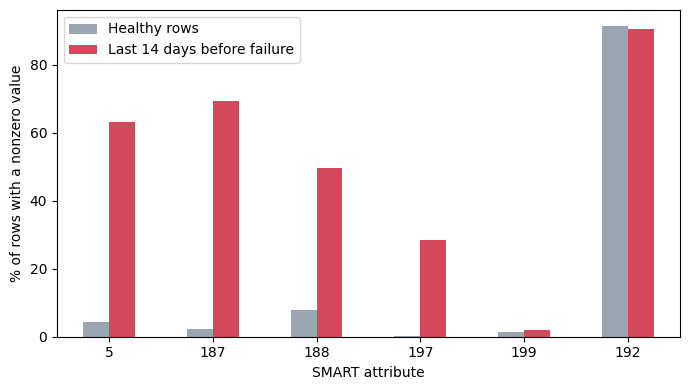

In [16]:
show = ["smart_5_raw", "smart_187_raw", "smart_188_raw", "smart_197_raw", "smart_199_raw", "smart_192_raw"]
plot_df = out.loc[show, ["healthy_%nonzero", "failed_%nonzero"]]
plot_df.index = [c.replace("smart_", "").replace("_raw", "") for c in plot_df.index]

ax = plot_df.plot.bar(figsize=(7, 4), color=["#9aa5b1", "#d1495b"])
ax.set_ylabel("% of rows with a nonzero value")
ax.set_xlabel("SMART attribute")
ax.legend(["Healthy rows", "Last 14 days before failure"])
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## C9. Failing vs healthy: which columns differ

**Question.** Which attributes look different in the last 14 days before a failure than in healthy drives?

**Finding.** Compared by share of nonzero rows, failed drives (last 14 days) vs a 600,000-row healthy sample: 197/198 0.35% vs 28.5%; 187 2.1% vs 69.4%; 5 4.3% vs 63.2%; 188 7.9% vs 49.7%. Attributes 199 (1.4% vs 1.9%) and 192 (91.5% vs 90.6%) barely differ. For the continuous attributes (1, 4, 7, 9, 12, 190, 193, 240 to 242) medians are similar, and this test cannot judge them. The comparison mixes old damage with fresh onset, and healthy figures are per row.

**Decision.** Keep 5, 187, 188 and 197 as core inputs. 199 and 192 are weak candidates for removal, pending the trend plots. No continuous column is dropped yet. Rerun the warning-sign check (Section 4) with 187 and 188 added.

In [12]:
print(out[["healthy_%nonzero", "failed_%nonzero"]].to_string())

                      healthy_%nonzero  failed_%nonzero
smart_1_raw                      99.99            99.84
smart_4_raw                      99.99            99.84
smart_5_normalized               99.99            99.84
smart_5_raw                       4.26            63.19
smart_7_raw                      99.99            99.84
smart_9_raw                      99.99            99.82
smart_12_raw                     99.98            99.64
smart_187_normalized             99.99            99.84
smart_187_raw                     2.14            69.39
smart_188_normalized             99.99            99.84
smart_188_raw                     7.94            49.71
smart_190_raw                    99.99            99.84
smart_192_raw                    91.46            90.57
smart_193_raw                    99.99            99.84
smart_194_raw                    99.99            99.84
smart_195_raw                    99.99            99.84
smart_197_normalized             99.99          

## C10


In [13]:
CNT = ["smart_5_raw", "smart_187_raw", "smart_188_raw", "smart_197_raw"]
failed_ids = df.loc[df["failure"] == 1, "serial_number"]

f = df.loc[df["serial_number"].isin(failed_ids), ["serial_number", "date"] + CNT]
f = f.assign(db=(f.groupby("serial_number", observed=True)["date"].transform("max") - f["date"]).dt.days)
f = f[f["db"] < 14]

hid = df.loc[~df["serial_number"].isin(failed_ids), "serial_number"].drop_duplicates().sample(3000, random_state=0)
h = df.loc[df["serial_number"].isin(hid), ["serial_number"] + CNT]
h = h.groupby("serial_number", observed=True).tail(14)     # each drive's last 14 rows

for name, d in [("failed", f), ("healthy", h)]:
    g = d.groupby("serial_number", observed=True)[CNT]
    end, rise = g.last(), g.last() - g.first()
    print(name, "| level > 0 at end:", (end > 0).mean().round(3).to_dict())
    print(name, "| rose inside window:", (rise > 0).mean().round(3).to_dict())
del f, h; gc.collect()

failed | level > 0 at end: {'smart_5_raw': 0.72, 'smart_187_raw': 0.807, 'smart_188_raw': 0.606, 'smart_197_raw': 0.419}
failed | rose inside window: {'smart_5_raw': 0.567, 'smart_187_raw': 0.74, 'smart_188_raw': 0.472, 'smart_197_raw': 0.341}
healthy | level > 0 at end: {'smart_5_raw': 0.074, 'smart_187_raw': 0.041, 'smart_188_raw': 0.102, 'smart_197_raw': 0.008}
healthy | rose inside window: {'smart_5_raw': 0.011, 'smart_187_raw': 0.008, 'smart_188_raw': 0.005, 'smart_197_raw': 0.002}


0

In [ ]:
cols = [c for c in df.columns if c.startswith("smart_") and "normalized" not in c]
failed_ids = df.loc[df["failure"] == 1, "serial_number"]

f = df.loc[df["serial_number"].isin(failed_ids), ["serial_number", "date"] + cols]
f = f.assign(db=(f.groupby("serial_number", observed=True)["date"].transform("max") - f["date"]).dt.days)
f = f[f["db"] < 14].drop(columns=["date", "db"])

hid = df.loc[~df["serial_number"].isin(failed_ids), "serial_number"].drop_duplicates().sample(10000, random_state=0)
h = df.loc[df["serial_number"].isin(hid), ["serial_number"] + cols].groupby("serial_number", observed=True).tail(14)

res = {}
for name, d in [("failed", f), ("healthy", h)]:
    g = d.groupby("serial_number", observed=True)[cols]
    res[name] = ((g.last() - g.first()) != 0).mean() * 100     # % of drives whose value changed
print(pd.DataFrame(res).round(1).to_string())
del f, h; gc.collect()

## C9b . Which other columns change before failure

**Question.** Beyond 5, 187, 188 and 197, do any of the other attributes change inside the last 14 days more often for failing drives?

**Finding.** Share of drives whose value changed in the window, failed (last 14 days) vs 10,000 healthy drives: 4: 25.9% vs 2.5%; 12: 12.7% vs 2.4%; 190/194: 67.9% vs 51.0%; 192: 24.8% vs 17.7%; 199: 0.4% vs 0.2%. Attributes 1, 7, 9, 193, 195 and 240 to 242 change on nearly every drive, so this test cannot judge them.

**Decision.** Add 4 and 12 as candidate inputs (check whether they duplicate each other). Temperature and 192 are weak candidates. 199 is a drop candidate. For the always-changing columns, judge by trend plots and model validation.

## C10. Level or change

**Question.** Is it better to give the model the counter's level, or how much it changed inside the window?

**Finding.** Failed drives (last 14 days) vs 3,000 healthy drives (last 14 rows). Level > 0 at the end: smart_5 72% vs 7.4%, 187 81% vs 4.1%, 188 61% vs 10.2%, 197 42% vs 0.8%. Rose inside the window: 5 57% vs 1.1%, 187 74% vs 0.8%, 188 47% vs 0.5%, 197 34% vs 0.2%. Healthy rates for 188 and 197 rest on only a few drives.

**Decision.** Give the model both level and change (the daily difference) for 5, 187, 188 and 197. Change separates the classes much better than level alone.

#### Checking if other columns changed before failure

               failed  healthy
smart_1_raw      99.4    100.0
smart_4_raw      25.9      2.5
smart_5_raw      57.8      1.1
smart_7_raw      99.4    100.0
smart_9_raw      99.4    100.0
smart_12_raw     12.7      2.4
smart_187_raw    74.0      0.9
smart_188_raw    47.2      0.5
smart_190_raw    67.9     51.0
smart_192_raw    24.8     17.7
smart_193_raw    99.2    100.0
smart_194_raw    67.9     51.0
smart_195_raw    99.4    100.0
smart_197_raw    36.0      0.4
smart_198_raw    36.0      0.4
smart_199_raw     0.4      0.2
smart_240_raw    99.4    100.0
smart_241_raw    99.2    100.0
smart_242_raw    99.4    100.0


0

## C11

             failures  drive_days  drive_years  failures_per_100_drive_years
smart_9_raw                                                                 
[0, 1)             27      130784        358.0                          7.54
[1, 2)             12      181332        497.0                          2.41
[2, 3)            112     2041198       5592.0                          2.00
[3, 4)            538     6755145      18507.0                          2.91
[4, 5)            469     6818994      18682.0                          2.51
[5, 6)            374     4832294      13239.0                          2.82
[6, 8)             14      298453        818.0                          1.71


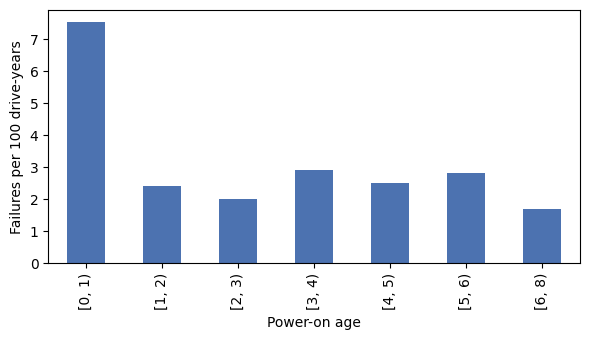

6744

In [17]:
age_y = df["smart_9_raw"] / 8760
band = pd.cut(age_y, [0, 1, 2, 3, 4, 5, 6, 8], right=False)
g = df.groupby(band, observed=True)["failure"].agg(failures="sum", drive_days="size")
g["drive_years"] = (g["drive_days"] / 365).round(0)
g["failures_per_100_drive_years"] = (g["failures"] / g["drive_years"] * 100).round(2)
print(g)

ax = g["failures_per_100_drive_years"].plot.bar(figsize=(6, 3.5), color="#4c72b0")
ax.set_ylabel("Failures per 100 drive-years"); ax.set_xlabel("Power-on age")
plt.tight_layout(); plt.show()
del age_y, band; gc.collect()

## C11. Power-on hours (drive age)

**Question.** Does the failure rate change with a drive's age?

**Finding.** Failures per 100 drive-years by age band: 0-1 years 7.54 (27 failures, 358 drive-years); 1-2: 2.41; 2-3: 2.00; 3-4: 2.91; 4-5: 2.51; 5-6: 2.82; 6-8: 1.71 (14 failures). From year 1 onward the rate stays between about 2 and 3 with no trend; the 0-1 and 6-8 bands rest on few failures. A first attempt grouping drives by age at their last row was discarded, because failed and healthy drives were measured at different dates.

**Decision.** Exclude `smart_9_raw` and its near-copy `smart_240_raw`. No clear age effect after year 1, Paper B dropped it for the same reason, and the end user may not know the drive's age.